# One GRU per sensor

**Temporal-stage notebook 5 in `notebooks/temporal/`.** `notebooks/temporal/README.md` says what the notebooks in this folder share. This notebook follows `04_lstm_fd001.ipynb` step for step and uses its words — memory slot, gate, projection — so read that one first.

## What this notebook is for

A **gated recurrent unit**, a GRU (Cho et al., 2014), is a simpler relative of the LSTM: it reads a sensor's readings one cycle at a time and carries a memory, like the LSTM, but it keeps one list where the LSTM keeps two and uses two gates where the LSTM uses three. This stage gives each sensor its own GRU, exactly as the LSTM stage gives each its own LSTM, with the same memory width, the same single layer and the same projection to one number. Those three sizes were chosen for the LSTM stage (assumption A-26, which covers the LSTM alone); the GRU stage borrows them, as its own entry in the assumptions log records (assumption A-36). `src/thesis_gnn_rul_xai/models/temporal/README.md` lists it among the stages.

It is **not the paper's stage**. The paper names a GRU only as one of the methods it compares against. It is here because it asks whether the paper's particular recurrent cell matters, at a smaller cost.

The notebook loads a trained network from a stored run, follows T50's 30 readings through T50's own trained GRU by hand, checks every number against PyTorch's, counts the cost and lists the stored results.

## What it does not do

- **It does not train anything.** The network is seed 42 of a stored five-seed run.
- **It does not explain what the trained network learned.**
- **It does not compare this stage with another.** `07_comparison_fd001.ipynb` does that.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Load the trained network and the window** | a stored run of this stage, seed 42 | the network, checked against the run; the held-back engine's last window |
| 2 | **Cycles 1 and 2 by hand** | T50's first two readings | the two gates, the proposal and the new memory, for three of the 32 memory slots |
| 3 | **All thirty cycles, and the number handed on** | T50's 30 readings | the memory cycle by cycle, and the one number T50's node receives |
| 4 | **Count the cost** | the network built with this stage | learned numbers, worked out by hand and counted |
| 5 | **Read the stored results** | `reports/` | every stored five-seed run of this stage under this folder's settings |

## 1. Background

### One memory, two gates

The LSTM keeps a memory its gates protect, the cell state, and a separate output computed from it. The GRU merges the two: its one list `h` is both the memory and the output. Two gates control it:

- the **reset gate** `r` decides how much of the old memory is used in building a proposal for the new one;
- the **update gate** `z` decides, slot by slot, how much of the old memory to keep and how much to replace by that proposal.

### The calculations at one cycle

Cho et al. print them as their Equations 5 to 8 (Section 2.3, page 3), one memory slot `j` at a time and with no offsets. Written for all slots at once, with the offsets PyTorch adds:

```
r_t = σ(W_r x_t + b_r + U_r h_{t−1} + c_r)              reset gate
z_t = σ(W_z x_t + b_z + U_z h_{t−1} + c_z)              update gate
h̃_t = tanh(W_h x_t + b_h + r_t ⊙ (U_h h_{t−1} + c_h))   proposal
h_t = z_t ⊙ h_{t−1} + (1 − z_t) ⊙ h̃_t                   new memory
```

- `x_t` is the sensor's reading at cycle `t`, one number; `h_{t−1}` is the memory after the previous cycle, 32 numbers, all zero before the first.
- `W_r`, `W_z`, `W_h` are learned multipliers of the reading, 32 each; `U_r`, `U_z`, `U_h` are learned multipliers of the old memory, 32 rows of 32 each.
- `b` and `c` are learned offsets, 32 each per gate: PyTorch keeps one list on the reading's side and one on the memory's side.
- `σ` squashes into 0 to 1, `tanh` into −1 to 1, and `⊙` multiplies slot by slot.

The last line is a weighted average of old and new in every slot: an update gate of 0.8 keeps 80 % of the old memory and takes 20 % of the proposal. **A tiny example, one slot:** old memory 0.5, proposal −0.4, update gate 0.8 gives `0.8 × 0.5 + 0.2 × (−0.4) = 0.40 − 0.08 = 0.32`.

**Do not confuse** PyTorch's GRU with Cho et al.'s on one point. Their Equation 8 multiplies the reset gate into the old memory *before* the multipliers `U` act on it, `U (r ⊙ h)`; PyTorch multiplies it into the result *after*, `r ⊙ (U h + c)`, offset included. The two can give different numbers whenever the reset gate differs between slots. This notebook computes PyTorch's version, because that is what the stage runs (assumption A-36), and step 3 checks the hand calculation against it.

**Do not confuse** the GRU's update gate with the LSTM's keep gate. Both decide how much old memory survives, but the LSTM's keep and add gates are separate, so it can keep all of the old memory and add a proposal on top; in the GRU what is kept and what is taken in always add up to one whole.

After the 30th cycle the stage turns `h_30`'s 32 numbers into one with the same kind of projection as the LSTM stage, `y = w · h_30 + b`, shared by the fourteen sensors, as in the LSTM stage.

## 2. Setup

In [1]:
from __future__ import annotations

import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

# The project's top folder is the nearest one above this notebook that holds
# pyproject.toml. Adding its src/ folder to Python's search path makes the
# package importable from a clone that was never installed.
PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook loads a trained network, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.models import ModelConfig, build_model
from thesis_gnn_rul_xai.training import evaluate_model, load_seed, read_run
from thesis_gnn_rul_xai.training import TrainingConfig, find_runs
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)    # a run's folder name is printed whole
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
PyTorch     : 2.13.0+cpu


## 3. The trained network and the window

### Step 1 — Load the trained network and the window

**What.** Load seed 42 of the sensitivity study's five-seed run of this stage, with its data rebuilt as it was trained, and take the folder's window.

**Why.** For the same reasons as in the LSTM notebook: a recurrent stage computes nothing meaningful untrained, and a stored run names its commit. It was trained on a graphics card and is scored here on the processor, so the check allows for differences in the last digits.

**Check.** The loaded network must score the test engines as the run recorded for seed 42, to within 0.0001 cycles; the run's settings must be this folder's; the window must pass the folder's checks.

In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
RUN = PROJECT_ROOT / "reports" / "sensitivity_fd65a3b-dirty_20260929T101059Z" / "runs" / "FD001" / "temporal_gru"
if not (RUN / "summary.json").is_file():
    raise FileNotFoundError(
        f"{RUN} is not in reports/. It is the sensitivity study's five-seed run of this stage. "
        "A run with the same settings is made with\n\n"
        "    python scripts/train.py --config config/fd001.yaml --temporal gru --seeds 5\n\n"
        "after which RUN above must name the folder it writes."
    )
run = read_run(RUN)
SEED = 42
network, prepared = load_seed(run, SEED)

recorded = float(run.results.set_index("seed").loc[SEED, "rmse"])
scored = evaluate_model(network, prepared.test)["rmse"]
same_network = abs(scored - recorded) < 1e-4
assert same_network
without_notes = lambda settings: {k: v for k, v in settings.to_dict().items() if k != "notes"}
same_settings = (without_notes(run.preprocessing) == without_notes(config)
                 and run.model_config == ModelConfig(temporal="gru"))
assert same_settings
command = run.summary["command"]
device = command[command.index("--device") + 1] if "--device" in command else "auto"
print(f"Stored run : {RUN.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Commit     : {run.summary['commit']}   trained with --device {device}, "
      f"PyTorch {run.summary['environment']['packages']['torch']}")
print(f"OK  seed {SEED}'s network scores the test engines at {scored:.6f} cycles here; the run "
      f"recorded {recorded:.6f} ({scored - recorded:+.1e}).")
print("OK  the run's preprocessing is config/fd001.yaml's, and its network is this stage's default.")

Stored run : reports/sensitivity_fd65a3b-dirty_20260929T101059Z/runs/FD001/temporal_gru
Commit     : fd65a3b-dirty   trained with --device cuda, PyTorch 2.5.1+cu121
OK  seed 42's network scores the test engines at 11.894712 cycles here; the run recorded 11.894712 (-6.1e-07).
OK  the run's preprocessing is config/fd001.yaml's, and its network is this stage's default.


In [3]:
sensors = list(prepared.sensor_symbols)

# The held-back engine with the most windows, and its last window.
held_back = prepared.validation
units, counts = np.unique(held_back.units, return_counts=True)
ENGINE = int(units[np.argmax(counts)])
engine_rows = np.flatnonzero(held_back.units == ENGINE)
engine_rows = engine_rows[np.argsort(held_back.end_cycles[engine_rows])]

SENSOR = "T50"
s = sensors.index(SENSOR)
window = held_back.features[engine_rows[-1]]             # (14 sensors, 30 cycles)
end_cycle = int(held_back.end_cycles[engine_rows[-1]])
cycles = np.arange(end_cycle - window.shape[1] + 1, end_cycle + 1)
readings = window[s]                                     # T50's 30 readings, oldest first

print(f"Engine {ENGINE}: {len(engine_rows)} windows, held back from training under seed {config.seed}.")
print(f"Worked window: cycles {cycles[0]} to {cycles[-1]}, shape {window.shape}, "
      f"remaining life at its end {held_back.targets[engine_rows[-1]]:.0f} cycles.\n")
display(pd.DataFrame([readings], index=[f"{SENSOR} reading"],
                     columns=pd.MultiIndex.from_arrays([range(1, 31), cycles],
                                                       names=["position", "engine cycle"])).round(6))

window_checks = {
    "the window is 14 sensors by 30 cycles": window.shape == (14, 30),
    "its engine is not a training engine": ENGINE not in set(prepared.train.units),
    "it ends at the cycle the engine failed": float(held_back.targets[engine_rows[-1]]) == 0.0,
}
assert all(window_checks.values()), window_checks
print("OK  " + "; ".join(window_checks))

Engine 5: 240 windows, held back from training under seed 42.
Worked window: cycles 240 to 269, shape (14, 30), remaining life at its end 0 cycles.



position,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
engine cycle,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269
T50 reading,1.292245,1.830854,1.37155,1.249616,1.447051,1.508854,1.587562,1.273505,1.471704,1.650684,1.835789,1.791576,1.52075,1.631635,1.756066,2.040374,2.416119,2.142862,2.213197,1.791471,1.891658,1.690612,1.812787,1.652386,1.828773,1.867343,2.481498,2.537435,2.828042,2.74036


OK  the window is 14 sensors by 30 cycles; its engine is not a training engine; it ends at the cycle the engine failed


## 4. The stage, step by step

### Step 2 — Cycles 1 and 2, by hand

**What.** Take T50's own GRU out of the trained network and compute cycles 1 and 2 with NumPy, showing the first three of the 32 memory slots. Each row of a table is one slot of one part, written as the four pieces the section 1 equations add: the reading times its multiplier, the reading side's offset, the old memory times its 32 multipliers, and the memory side's offset. For the two gates the memory side is added whole, so the column for the reset gate shows 1; for the proposal it is first multiplied by that slot's reset gate. Then the sum, and the sum squashed.

**Why.** At cycle 1 the old memory is all zeros, so its column is zero and each part is the reading's piece plus the two offsets. At cycle 2 the old memory takes part, and that one column is the whole difference between a recurrent network and one that reads each cycle on its own.

In [4]:
cell = network.temporal.cells[s]                       # T50's own GRU, one of fourteen
H = cell.hidden_size                                   # 32 memory slots
w_reading = cell.weight_ih_l0.detach().double().numpy()[:, 0]   # (96,)    multipliers of the reading
w_memory = cell.weight_hh_l0.detach().double().numpy()          # (96, 32) multipliers of the old memory
b_reading = cell.bias_ih_l0.detach().double().numpy()           # (96,)    offsets on the reading's side
b_memory = cell.bias_hh_l0.detach().double().numpy()            # (96,)    offsets on the memory's side
PARTS = {"reset": slice(0, H), "update": slice(H, 2 * H), "proposal": slice(2 * H, 3 * H)}
x = readings.astype(np.float64)
SLOTS = [0, 1, 2]


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def gru_cycle(reading, old):
    """One cycle of PyTorch's GRU, for all 32 slots at once."""
    from_reading = w_reading * reading + b_reading
    from_memory = w_memory @ old + b_memory
    reset = sigmoid(from_reading[PARTS["reset"]] + from_memory[PARTS["reset"]])
    update = sigmoid(from_reading[PARTS["update"]] + from_memory[PARTS["update"]])
    proposal = np.tanh(from_reading[PARTS["proposal"]] + reset * from_memory[PARTS["proposal"]])
    return {"from reading": from_reading, "from memory": from_memory, "reset": reset,
            "update": update, "proposal": proposal, "memory": update * old + (1 - update) * proposal}


def gate_table(step, reading, old):
    rows = []
    for part, where in PARTS.items():
        for k in SLOTS:
            memory_side = step["from memory"][where][k]
            # The proposal's memory side is multiplied by the reset gate before it is added.
            weight = step["reset"][k] if part == "proposal" else 1.0
            rows.append({"part": part, "slot": k + 1,
                         "multiplier × reading": w_reading[where][k] * reading,
                         "offset, reading side": b_reading[where][k],
                         "multipliers × old memory": (w_memory[where] @ old)[k],
                         "offset, memory side": b_memory[where][k],
                         "reset applied to the memory side": weight,
                         "sum": step["from reading"][where][k] + weight * memory_side,
                         "squashed": step[part][k]})
    return pd.DataFrame(rows).set_index(["part", "slot"])


zero = np.zeros(H)
first = gru_cycle(x[0], zero)
second = gru_cycle(x[1], first["memory"])
for number, step, old in ((1, first, zero), (2, second, first["memory"])):
    print(f"Cycle {number} (engine cycle {cycles[number - 1]}): reading {x[number - 1]:.6f}.")
    display(gate_table(step, x[number - 1], old).round(6))
    for k in SLOTS:
        print(f"  slot {k + 1}: new memory = update × old + (1 − update) × proposal = "
              f"{step['update'][k]:.6f} × {old[k]:+.6f} + {1 - step['update'][k]:.6f} × "
              f"{step['proposal'][k]:+.6f} = {step['memory'][k]:+.6f}")
    print()
k = 0
reading_side = second["from reading"][PARTS["proposal"]][k]
memory_side = second["from memory"][PARTS["proposal"]][k]
reset_times_memory = second["reset"][k] * memory_side
print(f"Proposal, slot 1, cycle 2: reading side {reading_side:+.6f}, memory side {memory_side:+.6f};")
print(f"  reset × memory side = {second['reset'][k]:.6f} × {memory_side:+.6f} = {reset_times_memory:+.6f}")
print(f"  proposal = tanh({reading_side:+.6f} + {reset_times_memory:+.6f}) = "
      f"tanh({reading_side + reset_times_memory:+.6f}) = {second['proposal'][k]:+.6f}")
print(f"Reset gate, slot 1, cycle 1: σ({first['from reading'][PARTS['reset']][k] + first['from memory'][PARTS['reset']][k]:+.7f}) "
      f"= {first['reset'][k]:.6f}, the sum to seven places")

Cycle 1 (engine cycle 240): reading 1.292245.


multiplier × reading  offset, reading side  multipliers × old memory  offset, memory side  \
part     slot                                                                                              
reset    1                 0.419560             -0.120759                       0.0            -0.045548   
         2                 0.039934             -0.006386                       0.0             0.075889   
         3                -0.178673              0.102714                       0.0            -0.210926   
update   1                 0.009727             -0.117475                       0.0            -0.171515   
         2                -0.040585             -0.127131                       0.0            -0.379232   
         3                -0.117877             -0.449849                       0.0            -0.475224   
proposal 1                -0.354050              0.053287                       0.0            -0.128230   
         2                -0.267479              0.094731                       0.0            -0.052254   
         3                 0.297045              0.097613                       0.0            -0.146181   

               reset applied to the memory side       sum  squashed  
part     slot                                                        
reset    1                             1.000000  0.253254  0.562977  
         2                             1.000000  0.109437  0.527332  
         3                             1.000000 -0.286885  0.428767  
update   1                             1.000000 -0.279262  0.430635  
         2                             1.000000 -0.546948  0.366573  
         3                             1.000000 -1.042950  0.260581  
proposal 1                             0.562977 -0.372953 -0.356572  
         2                             0.527332 -0.200303 -0.197666  
         3                             0.428767  0.331980  0.320299

  slot 1: new memory = update × old + (1 − update) × proposal = 0.430635 × +0.000000 + 0.569365 × -0.356572 = -0.203020
  slot 2: new memory = update × old + (1 − update) × proposal = 0.366573 × +0.000000 + 0.633427 × -0.197666 = -0.125207
  slot 3: new memory = update × old + (1 − update) × proposal = 0.260581 × +0.000000 + 0.739419 × +0.320299 = +0.236835

Cycle 2 (engine cycle 241): reading 1.830854.


multiplier × reading  offset, reading side  multipliers × old memory  offset, memory side  \
part     slot                                                                                              
reset    1                 0.594434             -0.120759                  0.179205            -0.045548   
         2                 0.056579             -0.006386                  0.091265             0.075889   
         3                -0.253145              0.102714                  0.354414            -0.210926   
update   1                 0.013782             -0.117475                 -0.481215            -0.171515   
         2                -0.057501             -0.127131                 -0.539069            -0.379232   
         3                -0.167009             -0.449849                 -0.220062            -0.475224   
proposal 1                -0.501619              0.053287                 -0.253996            -0.128230   
         2                -0.378964              0.094731                  0.000561            -0.052254   
         3                 0.420853              0.097613                 -0.195474            -0.146181   

               reset applied to the memory side       sum  squashed  
part     slot                                                        
reset    1                             1.000000  0.607332  0.647332  
         2                             1.000000  0.217346  0.554124  
         3                             1.000000 -0.006943  0.498264  
update   1                             1.000000 -0.756423  0.319423  
         2                             1.000000 -1.102933  0.249191  
         3                             1.000000 -1.312143  0.212128  
proposal 1                             0.647332 -0.695758 -0.601669  
         2                             0.554124 -0.312878 -0.303053  
         3                             0.498264  0.348232  0.334807

  slot 1: new memory = update × old + (1 − update) × proposal = 0.319423 × -0.203020 + 0.680577 × -0.601669 = -0.474331
  slot 2: new memory = update × old + (1 − update) × proposal = 0.249191 × -0.125207 + 0.750809 × -0.303053 = -0.258735
  slot 3: new memory = update × old + (1 − update) × proposal = 0.212128 × +0.236835 + 0.787872 × +0.334807 = +0.314024

Proposal, slot 1, cycle 2: reading side -0.448332, memory side -0.382225;
  reset × memory side = 0.647332 × -0.382225 = -0.247427
  proposal = tanh(-0.448332 + -0.247427) = tanh(-0.695758) = -0.601669
Reset gate, slot 1, cycle 1: σ(+0.2532538) = 0.562977, the sum to seven places


**Reading the tables.** Every number here is printed to six decimal places, so adding up printed numbers can differ from the printed total in the sixth place; where that happens below, the total is quoted as the code printed it.

At cycle 1 the old memory's column is zero, so each part is the reading's piece plus the two offsets. Slot 1's reset gate is the sigmoid of 0.419560 − 0.120759 + 0 − 0.045548, a sum the last line printed to seven places as 0.2532538, and σ(0.2532538) = 0.562977. Its update gate is 0.430635, so slot 1 keeps 43 % of an empty memory, which adds nothing, and takes 57 % of its proposal, −0.356572: its memory becomes 0.569365 × (−0.356572) = −0.203020.

At cycle 2 the old memory's column fills in. For slot 1's update gate it is −0.481215, enough to pull the gate from 0.43 down to 0.32, so slot 1 now keeps 32 % of its old −0.203020 and takes 68 % of a new proposal. The lines printed under the second table build that proposal. Its reading side is −0.501619 + 0.053287 = −0.448332. Its memory side is −0.253996 − 0.128230, printed as −0.382225 because the two pieces were rounded separately. The reset gate, 0.647332, times the memory side gives −0.247427. And the proposal is tanh of the sum of the two sides, printed as tanh(−0.695758) = −0.601669. The new memory is 0.319423 × (−0.203020) + 0.680577 × (−0.601669) = −0.474331.

### Step 3 — All thirty cycles, and the number handed on

**What.** Run the same calculation through all 30 cycles, applying the projection at each one to see what the stage would hand on if the window ended there.

**Why.** The last row is the stage's whole result for T50, and the rows before it show how the memory got there.

**Check.** The hand memory must match PyTorch's GRU at every cycle, and the final number must match what the trained stage hands T50's node, both to within 0.00001.

,engine cycle,reading,"update, average of 32","reset, average of 32",handed on if the window ended here
position,,,,,
1,240,1.2922,0.5191,0.5207,0.3433
2,241,1.8309,0.5112,0.5369,0.8606
3,242,1.3715,0.4848,0.5404,1.0199
4,243,1.2496,0.4681,0.5453,1.1197
5,244,1.4471,0.4589,0.5506,1.2817
6,245,1.5089,0.4497,0.5532,1.3988
7,246,1.5876,0.4421,0.5557,1.4964
8,247,1.2735,0.4341,0.5534,1.4553
9,248,1.4717,0.4327,0.5561,1.5277


Update gates over all 32 slots and 30 cycles: from 0.0466 to 0.9986; 101 of 960 above 0.9.

Projection of cycle 30's memory: (-0.1893 × -0.9647) + (-0.1054 × -0.4291) + (+0.0834 × -0.0126) + ... 29 more + offset -0.1339 = +2.072320

OK  the hand memory matches PyTorch's GRU at all 30 cycles (largest gap 1.7e-07), and the stage hands T50's node 2.072320.

What the stage hands every sensor's node for this window:


,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32
handed on,1.0526,0.1587,2.0723,-0.1682,-0.0316,0.311,2.7868,1.6895,0.3133,0.8058,1.24,0.342,0.3317,0.5626


Across engine 5's 240 windows, the correlation of T50's handed-on number with


  the window's newest reading  +0.977
  the window's average         +0.987


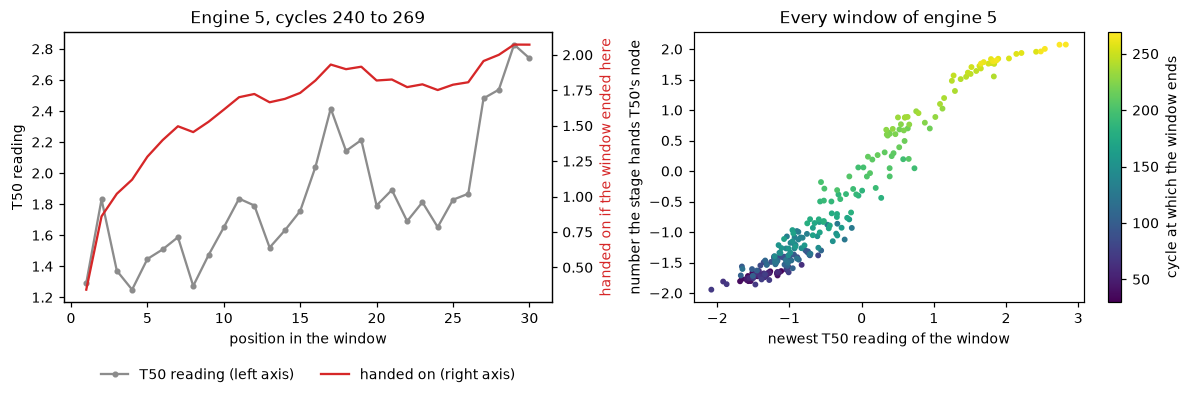

In [5]:
w_project = network.temporal.project.weight.detach().double().numpy()[0]   # (32,), shared by all sensors
b_project = float(network.temporal.project.bias.detach())

memory, trace, memories, updates = zero, [], [], []
for t in range(30):
    step = gru_cycle(x[t], memory)
    memory = step["memory"]
    memories.append(memory)
    updates.append(step["update"])
    trace.append({"engine cycle": cycles[t], "reading": x[t], "update, average of 32": step["update"].mean(),
                  "reset, average of 32": step["reset"].mean(),
                  "handed on if the window ended here": w_project @ memory + b_project})
trace = pd.DataFrame(trace, index=pd.Index(range(1, 31), name="position"))
display(trace.round(4))
updates = np.array(updates)
print(f"Update gates over all 32 slots and 30 cycles: from {updates.min():.4f} to {updates.max():.4f}; "
      f"{(updates > 0.9).sum()} of {updates.size} above 0.9.\n")

terms = w_project * memory
print("Projection of cycle 30's memory: "
      + " + ".join(f"({w_project[j]:+.4f} × {memory[j]:+.4f})" for j in range(3))
      + f" + ... 29 more + offset {b_project:+.4f} = {terms.sum() + b_project:+.6f}")

with torch.no_grad():
    torch_memories = cell(torch.from_numpy(window[s][None, :, None]))[0][0].double().numpy()   # (30, 32)
    handed_on = network.temporal(torch.from_numpy(window[None]))                                # (1, 14, 1)
hand_matches_gru = bool(np.abs(np.array(memories) - torch_memories).max() < 1e-5)
hand_matches_stage = bool(abs(trace.iloc[-1, -1] - float(handed_on[0, s, 0])) < 1e-5)
assert hand_matches_gru and hand_matches_stage
print(f"\nOK  the hand memory matches PyTorch's GRU at all 30 cycles "
      f"(largest gap {np.abs(np.array(memories) - torch_memories).max():.1e}), and the stage hands "
      f"T50's node {float(handed_on[0, s, 0]):.6f}.\n")
print("What the stage hands every sensor's node for this window:")
display(pd.DataFrame({"handed on": handed_on[0, :, 0].numpy()}, index=sensors).T.round(4))

with torch.no_grad():
    life_out = network.temporal(torch.from_numpy(held_back.features[engine_rows]))[:, s, 0].numpy()
life_newest = held_back.features[engine_rows, s, -1]
life_average = held_back.features[engine_rows, s, :].mean(axis=1)
with_newest = np.corrcoef(life_out, life_newest)[0, 1]
with_average = np.corrcoef(life_out, life_average)[0, 1]
print(f"Across engine {ENGINE}'s {len(engine_rows)} windows, the correlation of T50's handed-on number with")
print(f"  the window's newest reading  {with_newest:+.3f}")
print(f"  the window's average         {with_average:+.3f}")

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
reading_line, = left.plot(trace.index, trace["reading"], "o-", color="0.55", markersize=3,
                         label=f"{SENSOR} reading (left axis)")
left.set(xlabel="position in the window", ylabel=f"{SENSOR} reading",
         title=f"Engine {ENGINE}, cycles {cycles[0]} to {cycles[-1]}")
twin = left.twinx()
handed_line, = twin.plot(trace.index, trace["handed on if the window ended here"], color="C3",
                         label="handed on (right axis)")
twin.set_ylabel("handed on if the window ended here", color="C3")
# One legend for both lines, under the panel, where it covers neither.
left.legend(handles=[reading_line, handed_line], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2,
            frameon=False)
dots = right.scatter(life_newest, life_out, s=8, c=held_back.end_cycles[engine_rows], cmap="viridis")
figure.colorbar(dots, ax=right, label="cycle at which the window ends")
right.set(xlabel=f"newest {SENSOR} reading of the window", ylabel="number the stage hands T50's node",
          title=f"Every window of engine {ENGINE}")
figure.tight_layout()
plt.show()

**Reading the table and the figure.** As in the LSTM notebook, the number the stage would hand on moves most over the first seven cycles, here rising from 0.34 to 1.50 while T50 wavers between 1.25 and 1.83: the memory filling up from zero, which every window repeats. After that it follows T50, and over the last four cycles, when T50 jumps from 1.87 to between 2.48 and 2.83, it rises from 1.81 to 2.07.

The update gates average between 0.41 and 0.52 over the 32 slots at every cycle, while single gates range from 0.047 to 0.999. An update gate near 1 keeps the old memory, and 101 of the 960 computed here are above 0.9.

Across the engine's life (right) the number rises as T50's newest reading rises, with a correlation of +0.977 — a number from −1 to +1 that says how closely two lists of numbers follow a straight line together, +1 for a perfect rising line, −1 for a perfect falling one, as the LSTM notebook's step 4 explains — and +0.987 with the window's average. The LSTM notebook's network moved the other way, with correlations of −0.967 and −0.977. The sign carries no meaning on its own, because the first graph layer multiplies the number by 32 learned multipliers that can take either sign; what the two networks share is that for T50 the trained stage hands on something that tracks where T50 sits, a little more closely the window's average than its newest reading. Each is one network, seed 42's.

### Step 4 — What it costs

**What.** Work out the stage's learned numbers by hand, then build the network with this stage, and with one GRU shared by all sensors, and count.

**Why.** A GRU has three blocks of multipliers and offsets where an LSTM has four, so the stage should cost three quarters of the LSTM stage's cells, plus the same projection.

**Check.** The hand count must equal the count of the built networks and of the loaded one.

In [6]:
TABLE_4_NAMES = {"graph_layers.0": "GCN-1", "graph_layers.1": "GCN-2",
                 "graph_layers.2": "GCN-3", "fc1": "FC-1", "fc2": "FC-2"}


def parameter_table(network):
    """Learned numbers in each part of a network, the temporal stage first."""
    parts = {"temporal stage": 0}
    for name, parameter in network.named_parameters():
        part = "temporal stage" if name.startswith("temporal.") else TABLE_4_NAMES[name.rsplit(".", 1)[0]]
        parts[part] = parts.get(part, 0) + parameter.numel()
    parts["whole network"] = sum(parts.values())
    return pd.DataFrame({"learned numbers": parts})


per_cell = 3 * H * 1 + 3 * H * H + 2 * 3 * H     # reading multipliers + memory multipliers + two offset lists
projection = H + 1
print(f"one GRU:   3 × {H} × 1 + 3 × {H} × {H} + 2 × 3 × {H} = {3 * H} + {3 * H * H} + {6 * H} = {per_cell:,}")
print(f"the stage: 14 × {per_cell:,} + ({H} + 1) = {14 * per_cell + projection:,}")
print(f"shared:    {per_cell:,} + ({H} + 1) = {per_cell + projection:,}\n")

built = {}
for name, shared in (("one GRU per sensor", False), ("one GRU for all sensors", True)):
    model = build_model(prepared.adjacency_normalized, ModelConfig(temporal="gru", shared_across_sensors=shared),
                        window_size=config.window_size, rul_max=config.rul_max)
    built[name] = parameter_table(model)["learned numbers"]
costs = pd.DataFrame(built)
display(costs.T)
cost_checks = {
    "one GRU per sensor": int(costs.loc["temporal stage", "one GRU per sensor"]) == 14 * per_cell + projection,
    "one shared GRU": int(costs.loc["temporal stage", "one GRU for all sensors"]) == per_cell + projection,
    "the loaded network": network.count_parameters() == int(costs.loc["whole network", "one GRU per sensor"]),
    "the rest is Table 4's 61,729": int(costs.loc["whole network", "one GRU per sensor"]) - (14 * per_cell + projection) == 61_729,
}
assert all(cost_checks.values()), cost_checks
print("OK  the hand counts match: " + "; ".join(cost_checks))

one GRU:   3 × 32 × 1 + 3 × 32 × 32 + 2 × 3 × 32 = 96 + 3072 + 192 = 3,360
the stage: 14 × 3,360 + (32 + 1) = 47,073
shared:    3,360 + (32 + 1) = 3,393



,temporal stage,GCN-1,GCN-2,GCN-3,FC-1,FC-2,whole network
one GRU per sensor,47073,32,2048,2048,57472,129,108802
one GRU for all sensors,3393,32,2048,2048,57472,129,65122


OK  the hand counts match: one GRU per sensor; one shared GRU; the loaded network; the rest is Table 4's 61,729


### Step 5 — The stored results of this stage

**What.** Every stored five-seed run that used this stage, with one GRU per sensor or one shared, under this folder's settings. Runs that saved only part of their settings — the oldest saved nothing about their training but the learning-rate path — are listed with what they did not save, and their seeds are set beside those of the runs that saved everything.

**Why.** As for every stage, an error in cycles belongs to the whole trained network and its settings.

In [7]:
STUDY = PROJECT_ROOT / "reports" / "sensitivity_fd65a3b-dirty_20260929T101059Z" / "runs" / "FD001"
DEFAULT_TRAINING = TrainingConfig()
TRAINING_FIELDS = ("epochs", "batch_size", "learning_rate", "final_learning_rate",
                   "early_stopping_patience", "lr_schedule")
WANTED = [ModelConfig(temporal="gru"), ModelConfig(temporal="gru", shared_across_sensors=True)]


def training_settings(run) -> str:
    """'default' or 'other' from the training settings a run saved; 'not saved' if it saved only the learning-rate path."""
    recorded = run.summary.get("training")
    if recorded is None:
        return "not saved" if run.summary.get("lr_schedule") == DEFAULT_TRAINING.lr_schedule else "other"
    default = all(recorded.get(field) == getattr(DEFAULT_TRAINING, field) for field in TRAINING_FIELDS)
    return "default" if default else "other"


def not_saved(run) -> str:
    """The settings a run did not save, or a dash if it saved them all."""
    missing = [] if run.summary.get("training") else ["training settings"]
    if not (run.path / "model_config.yaml").is_file():
        missing.append("network sizes" if "temporal_stage" in run.summary else "network sizes, stage")
    return ", ".join(missing) or "—"


def machine(run) -> str:
    """The device a run's first seed asked for, and the PyTorch build the run recorded."""
    saved = run.path / f"seed_{run.seeds[0]}" / "training_config.yaml"
    device = yaml.safe_load(saved.read_text(encoding="utf-8")).get("device") if saved.is_file() else None
    build = ((run.summary.get("environment") or {}).get("packages") or {}).get("torch")
    return f"{device or 'not recorded'}, PyTorch {build or 'not recorded'}"


stored = [
    run
    for root in (None, STUDY)
    for run in find_runs(root=root, preprocessing=config, seeds=5, split="varies_with_seed",
                         early_stopping=True)
    if run.model_config in WANTED and training_settings(run) != "other"
]
print("Settings every run below shares, where it saved them:")
print("  preprocessing:", {k: v for k, v in config.to_dict().items() if k != "notes"})
print("  training:     ", {field: getattr(DEFAULT_TRAINING, field) for field in TRAINING_FIELDS},
      "and the pass that scored best on the held-back engines restored")
for model_config in WANTED:
    print("  network:      ", model_config.to_dict())
print()
if stored:
    display(pd.DataFrame([{
        "run, under reports/": run.path.resolve().relative_to((PROJECT_ROOT / "reports").resolve()).as_posix(),
        "commit": run.summary["commit"],
        **({"one network for all sensors": run.model_config.shared_across_sensors}
           if len(WANTED) > 1 else {}),
        "device asked for, PyTorch build": machine(run),
        "not saved by the run": not_saved(run),
        "seeds": ", ".join(map(str, run.seeds)),
        "test RMSE": f"{run.results['rmse'].mean():.3f} ± {run.results['rmse'].std():.3f}",
        "held-back RMSE": f"{run.results['validation_rmse'].mean():.3f} ± "
                          f"{run.results['validation_rmse'].std():.3f}",
    } for run in stored]).set_index("run, under reports/"))
else:
    print("reports/ holds no five-seed run of this stage under these settings. Make one with\n\n"
          "    python scripts/train.py --config config/fd001.yaml --temporal gru --seeds 5\n")

# A run that saved less is set beside the runs that saved everything, seed by seed.
complete = [run for run in stored if not_saved(run) == "—"]
repeats = {}
for run in stored:
    if not_saved(run) == "—":
        continue
    mine = run.results.set_index("seed").sort_index()[["rmse", "validation_rmse"]].to_numpy()
    repeats[run.name] = [
        other.summary["commit"] for other in complete
        if np.array_equal(other.results.set_index("seed").sort_index()[["rmse", "validation_rmse"]].to_numpy(), mine)
    ]
    unsaid = not_saved(run).split(", ")
    unsaid = unsaid[0] if len(unsaid) == 1 else ", ".join(unsaid[:-1]) + " or " + unsaid[-1]
    twins = repeats[run.name]
    print(f"The run at {run.summary['commit']} saved no {unsaid}; its five seeds give the same test and held-back "
          f"RMSE, to every stored digit, as the run{'s' if len(twins) > 1 else ''} at {', '.join(twins) or 'no commit'}.")
unsaved_runs_repeat = all(repeats.values())

Settings every run below shares, where it saved them:
  preprocessing: {'subset': 'FD001', 'window_size': 30, 'window_stride': 1, 'rul_max': 125, 'clip_test_labels': True, 'normalization': 'zscore', 'smoothing_alpha': 0.5, 'graph': 'physics', 'adjacency_normalization': 'row', 'validation_fraction': 0.2, 'seed': 42}
  training:      {'epochs': 200, 'batch_size': 32, 'learning_rate': 0.001, 'final_learning_rate': 0.0001, 'early_stopping_patience': 20, 'lr_schedule': 'step'} and the pass that scored best on the held-back engines restored
  network:       {'temporal': 'gru', 'temporal_hidden': 32, 'temporal_out_features': 1, 'shared_across_sensors': False, 'gcn_hidden': [32, 64, 32], 'fc_hidden': 128, 'gcn_bias': False}
  network:       {'temporal': 'gru', 'temporal_hidden': 32, 'temporal_out_features': 1, 'shared_across_sensors': True, 'gcn_hidden': [32, 64, 32], 'fc_hidden': 128, 'gcn_bias': False}



,commit,one network for all sensors,"device asked for, PyTorch build",not saved by the run,seeds,test RMSE,held-back RMSE
"run, under reports/",,,,,,,
sensitivity_fd65a3b-dirty_20260929T101059Z/runs/FD001/temporal_gru,fd65a3b-dirty,False,"cuda, PyTorch 2.5.1+cu121",—,"42, 43, 44, 45, 46",12.818 ± 0.681,13.185 ± 0.634


**One stored run**, the sensitivity study's at `fd65a3b-dirty`, under the settings printed above. No run of one GRU shared by all sensors is stored; one would be made with `python scripts/train.py --config config/fd001.yaml --temporal gru --shared-across-sensors --seeds 5`.

**Which published row it may be set beside: none.** The row labelled GRU in the paper's Tables 7 to 10, 18.31 RMSE on FD001 in its Table 8, is one of the other methods the paper compares against (its reference 55), not the paper's network with a different recurrent cell.

## Final verification

In [8]:
checks = [
    ("The loaded network scores what the run recorded", same_network, f"{scored - recorded:+.1e} cycles"),
    ("The run's settings are this folder's", same_settings, run.summary["commit"]),
    ("The window is the folder's window", all(window_checks.values()), f"engine {ENGINE}, cycle {end_cycle}"),
    ("Hand memory matches PyTorch's GRU, 30 cycles", hand_matches_gru, "32 slots each"),
    ("Hand projection matches the stage", hand_matches_stage, f"{trace.iloc[-1, -1]:.6f}"),
    ("Hand parameter counts match the built networks", all(cost_checks.values()), "47,073 in the stage"),
    ("Each run that saved less repeats one that saved all", unsaved_runs_repeat, f"{len(repeats)} such run(s)"),
]
width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")
print(f"\nStored five-seed runs of this stage under this folder's settings: {len(stored)}; the step on stored results lists them, or prints the command that makes one.")
print(f"Measured, not checked: across engine {ENGINE}'s windows, T50's handed-on number correlates {with_newest:+.3f} with the newest reading and {with_average:+.3f} with the average, for this one network.")

CHECK                                                 RESULT   DETAIL
---------------------------------------------------------------------------------------------
The loaded network scores what the run recorded       PASS     -6.1e-07 cycles
The run's settings are this folder's                  PASS     fd65a3b-dirty
The window is the folder's window                     PASS     engine 5, cycle 269
Hand memory matches PyTorch's GRU, 30 cycles          PASS     32 slots each
Hand projection matches the stage                     PASS     2.072320
Hand parameter counts match the built networks        PASS     47,073 in the stage
Each run that saved less repeats one that saved all   PASS     0 such run(s)
---------------------------------------------------------------------------------------------
All 7 checks passed.

Stored five-seed runs of this stage under this folder's settings: 1; the step on stored results lists them, or prints the command that makes one.
Measured, not checked: acr

## Summary

### What this notebook produced

- **T50's 30 readings through T50's own trained GRU**, cycles 1 and 2 by hand for three memory slots and all thirty for all 32, each matched against PyTorch's.
- **The number handed on**, matched against the trained stage, and how it moves with T50's readings across an engine's life, for this one network.
- **Its cost**: 47,073 learned numbers in the stage, 108,802 in the network.
- **Its stored results**, with their commit and settings.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| A GRU at all | not the paper's stage; an alternative recurrent cell | A-36 |
| Memory width, depth, and the step to one number | the LSTM stage's: 32 slots, one layer, one shared projection | borrowed from the LSTM stage's choice (A-26), as the GRU stage's own entry records (A-36) |
| Starting values before training | PyTorch's own | A-34 |
| Restoring the pass that scored best on the held-back engines | yes | A-18 |
| Which window and which sensor are shown | the held-back engine's last window, T50 | `notebooks/temporal/README.md` |

### References

- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. *Proceedings of EMNLP 2014*, 1724-1734. Section 2.3, Equations 5 to 8.
- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement for aeroengine RUL prediction. *Aerospace Science and Technology*, 168, 110875. Table 4.